In [34]:
import numpy as np
import numpy.random as rnd
import matplotlib.pyplot as plt
%matplotlib inline

# Generación de datos de prueba

En el siguiente bloque se generan K cumulos diferentes junto con la etiquetas que le corresponden.

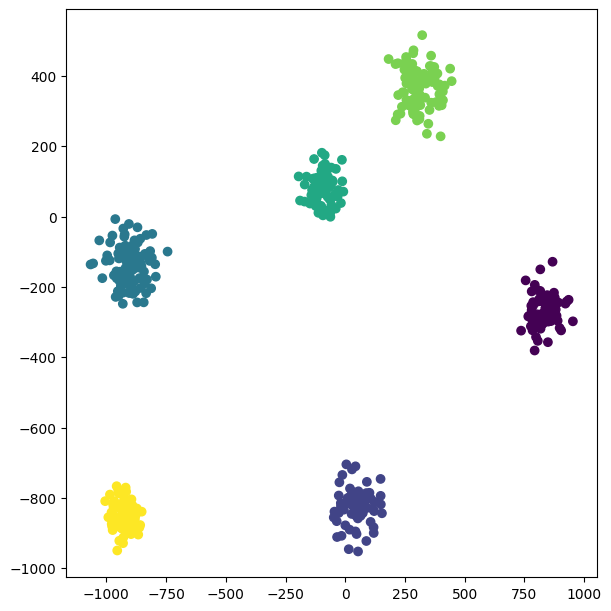

In [125]:

K=6

# Creamos Puntos aleatorios en 2 dimensiones que correspondan a K clase.

# Cada columna de la matriz almacena las coordenada promedio de la clase
# la varianza de la clase y cuantos puntos la conforman
C=np.zeros((4,K))

# Definimos los centroides como valores aleatorios en el rango
# x \in [0, xMax)
# y \in [0, yMax)
# La desviación estandar asociada a cada cumulo es un valor en el intervalo [sMin, sMax).
# El numero de puntos asociados a cada clase es un numero en el interval [nMin,nMax)
#
# Cada columna de la matriz C codifica los parametros de cada clase descritos arriba.
xMin, xMax, yMin, yMax, = -1000, 1000, -1000, 1000,
sMin, sMax, nMin, nMax = 40, 60, 70, 100
for i in range(K):
  C[:,i]= [rnd.randint(xMin, xMax),rnd.randint(yMin, yMax),\
           rnd.randint(sMin, sMax), rnd.randint(nMin, nMax)]

# N es el numero de datos que vamos a considerer
N = np.int32(np.sum(C[3,:]))

# Generamos los puntos
# Cada columna de la matriz p almacena un dato.
p = np.zeros((2,N))
# Cada elementos del arreglo c indica la clase a la que corresponde
c = np.zeros(N)
idx = 0
for i in range(K):
    n = np.int32(C[3, i])
    p[:,idx:idx+n] = rnd.randn(2,n) * C[2,i] + C[:2,i].reshape(2,1)
    c[idx:idx+n] = i
    idx += n

fig1, ax1 = plt.subplots(1, figsize=(6, 6), layout='constrained')
ax1.scatter(p[0,:], p[1,:], c=c)
plt.show()



In [126]:
# Calcula la distancia euclideana al cuadrado entre los vectores 'x' y 'y'.
def dEuclidSq(x,y):
  #dfV es la diferencia de los vectores
  dfV = x-y
  # El producto punto entre dfv y si mismo es equivalente
  # a la sumatoria del cuadrado de lo elementos de dfv
  # esto es, la distancia euclideana al cuadrado.
  return np.dot(dfV, dfV)


def Kmeans(p, K, itMax = 30):
  # n es el número de datos que tenemos.
  # se asume que p es una matriz con n columnas
  # donde cada una ella representa un dato.
  # El número de renlones de p corresponde al
  # número de dimensiones del arreglo.
  d, n = p.shape

  # c es u arreglo que define la clase a la que pertenece cada
  c = rnd.randint(0, K, n)

  # C es la matriz donde almacenaremos los centroides de las
  # clases que encontremos. Cada columna corresponde a un centroide.
  C=np.zeros((d, K))



  #Calculamos los Centroides Iniciales
  cont=np.zeros(K)
  for i in range(n):
    idx = c[i]
    C[:, idx] += p[:,i]
    cont[idx] += 1
  for i in range(K):
    if cont[i] != 0:
      C[:,i] /= cont[i]
    else:
      print("Error: Clase vacía")

  # En esta matriz almacenaremos el historial de los centroides.
  evolC = np.zeros((K * d,itMax+1))

  idx = 0
  for i in range(K):
    evolC[idx:idx+d,0] = C[:,i]
    idx += d


  # La variable cambio indica si hubo algun cambio en la definicion
  # de los centroides entre iteraciones.
  cambio = True
  iteracion = 0 # Contadore de iteraciones

  # Ciclo principal del programa
  while iteracion < itMax and cambio == True:
    print("Iteracion #", iteracion)

    #Calculamos las distancias entre cada punto y cada clase.
    for i in range(n):
      closest = 0
      difMin = dEuclidSq(p[:,i], C[:,0])
      for j in range(1,K):
        dif = dEuclidSq(p[:,i], C[:,j])
        if dif < difMin:
          difMin = dif
          closest = j
      c[i] = closest

    #Almacenamo el valor de los centroides en el historial.
    idx = 0
    for i in range(K):
      evolC[idx:idx+d, iteracion+1] = C[:,i]
      idx += d

    #Recalculamos los Centroides
    C_Old = C.copy()
    C=np.zeros((d, K))
    cont=np.zeros(K)
    for i in range(n):
      idx = c[i]
      C[:, idx] += p[:,i]
      cont[idx] += 1
    for i in range(K):
      if cont[i] != 0:
        C[:,i] /= cont[i]
      else:
        print("Error: Clase vacía")

    #Si no hubo cambios terminamos
    if (C_Old == C).all():
      cambio = False
    iteracion += 1

  return C, evolC[:,:iteracion+1]





Iteracion # 0
Error: Clase vacía
Error: Clase vacía
Iteracion # 1
Error: Clase vacía
Iteracion # 2
Iteracion # 3
Iteracion # 4
Iteracion # 5
Clases Estimadas  :
 [[  47.04307345  -90.5596502  -925.57719124  309.92623293 -905.63078536
   831.91204591]
 [-823.67011231   81.13638585 -851.34913235  364.91471421 -138.42147129
  -270.06287593]] 

Clases Originales :
 [[ 836.   39. -897.  -88.  321. -929.]
 [-274. -830. -135.   73.  371. -859.]] 



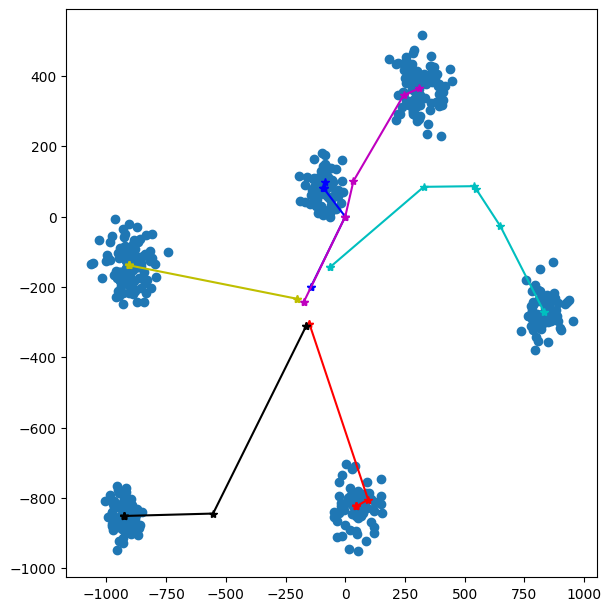

In [127]:
k = 6
Cestim, evolC =  Kmeans(p, k)

print
print ("Clases Estimadas  :\n", Cestim, "\n")
print ("Clases Originales :\n", C[:2,:], "\n")
fig2, ax2 = plt.subplots(1, figsize=(6, 6), layout='constrained')
ax2.scatter(p[0,:], p[1,:])


Color=['r', 'b', 'k', 'm', 'y', 'c']
for i in range(k):
  idx = i*2
  plt.plot(evolC[idx,:],evolC[idx+1,:],Color[i], evolC[idx,:],evolC[idx+1,:],"*"+Color[i])
plt.show()

In [115]:
evolC

array([[-223.15258747, -223.15258747, -275.78786971, -346.13643876,
        -370.63630224],
       [ -19.42227678,  -19.42227678,  415.12435383,  481.76992875,
         504.33843404],
       [-247.79038305, -247.79038305, -284.44366775, -284.44366775,
        -284.44366775],
       [-200.61291268, -200.61291268, -892.02144095, -892.02144095,
        -892.02144095],
       [-235.96207895, -235.96207895,    0.        ,  -62.61038773,
         -70.28293256],
       [-101.5710054 , -101.5710054 ,    0.        ,  213.1680662 ,
         221.82718004],
       [-198.65911731, -198.65911731,   -7.18001545,   -7.18001545,
          -7.18001545],
       [-177.15572645, -177.15572645, -290.45002825, -290.45002825,
        -290.45002825],
       [-265.34302639, -265.34302639,    0.        ,    0.        ,
           0.        ],
       [-182.41063502, -182.41063502,    0.        ,    0.        ,
           0.        ],
       [-265.87908052, -265.87908052,    0.        ,    0.        ,
           0